# Lab 4 — Bài tập mục 7

Nguyễn Đình Huy — MSSV: 2474802010140.

Mỗi mục có đúng một cell code. Chọn **Run All** để chạy từ trên xuống. Giữ ba CSV trong `data/`, hoặc tải trực tiếp vào Files trên Colab. Hình lưu trong `figures/`; chạy `scripts/run_all.py` để xuất nhật ký vào `outputs/`.

## Bài 1. Tự viết KNN không dùng thư viện

Tự tính khoảng cách Euclid, tìm 13 láng giềng và bỏ phiếu. scikit-learn chỉ dùng để chia tập và tạo mô hình đối chiếu.

In [1]:
from pathlib import Path

# Tìm dataset từ thư mục bài, code/ hoặc Files trên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "hai_vang_trang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

import numpy as np

def knn_du_doan(X_hoc, y_hoc, x_moi, k):
    khoang_cach = np.sqrt(((X_hoc - x_moi) ** 2).sum(axis=1))
    chi_so_gan = np.argsort(khoang_cach)[:k]
    cac_nhan, so_phieu = np.unique(y_hoc[chi_so_gan], return_counts=True)
    return cac_nhan[np.argmax(so_phieu)]

X_hoc, y_hoc = X_tr.to_numpy(), y_tr.to_numpy()
nhan_tu_viet = np.array([knn_du_doan(X_hoc, y_hoc, x_moi, 13) for x_moi in X_te.to_numpy()])
accuracy_tu_viet = (nhan_tu_viet == y_te.to_numpy()).mean()
model = KNeighborsClassifier(n_neighbors=13).fit(X_tr, y_tr)
nhan_thu_vien = model.predict(X_te)
print(f"Accuracy tự viết: {accuracy_tu_viet:.4f}")
print(f"Accuracy scikit-learn: {accuracy_score(y_te, nhan_thu_vien):.4f}")
print(f"Số nhãn dự đoán khác nhau: {np.count_nonzero(nhan_tu_viet != nhan_thu_vien)}")
print("Giải thích: Hàm tính khoảng cách tới từng mẫu học, chọn 13 mẫu gần nhất rồi trả về nhãn có nhiều phiếu nhất. Đây cũng là quy tắc của KNeighborsClassifier với khoảng cách Euclid và trọng số đều, nên kết quả trên cùng dữ liệu khớp nhau.")
print("k = 13 là số lẻ nên hai lớp không hòa phiếu; nhãn và đặc trưng phải luôn giữ cùng thứ tự sau khi chia dữ liệu.")


Accuracy tự viết: 0.9200
Accuracy scikit-learn: 0.9200
Số nhãn dự đoán khác nhau: 0
Giải thích: Hàm tính khoảng cách tới từng mẫu học, chọn 13 mẫu gần nhất rồi trả về nhãn có nhiều phiếu nhất. Đây cũng là quy tắc của KNeighborsClassifier với khoảng cách Euclid và trọng số đều, nên kết quả trên cùng dữ liệu khớp nhau.
k = 13 là số lẻ nên hai lớp không hòa phiếu; nhãn và đặc trưng phải luôn giữ cùng thứ tự sau khi chia dữ liệu.


## Bài 2. Khoảng cách Manhattan

Chạy lại cách chọn k của mục 4 với metric Manhattan, đối chiếu Euclid trên cùng phép chia. Chọn k bằng CV trên tập học.

In [2]:
from pathlib import Path

# Tìm dataset từ thư mục bài, code/ hoặc Files trên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "hai_vang_trang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

ket_qua = []
print("Khoảng cách    k tốt nhất    Accuracy CV    Accuracy kiểm tra")
for metric in ["euclidean", "manhattan"]:
    diem_cv = {}
    for k in range(1, 52, 2):
        model = KNeighborsClassifier(n_neighbors=k, metric=metric)
        diem_cv[k] = cross_val_score(model, X_tr, y_tr, cv=5).mean()
    k_tot = max(diem_cv, key=diem_cv.get)
    model = KNeighborsClassifier(n_neighbors=k_tot, metric=metric).fit(X_tr, y_tr)
    acc = accuracy_score(y_te, model.predict(X_te))
    ket_qua.append((metric, k_tot, diem_cv[k_tot], acc))
    print(f"{metric:12s}   {k_tot:4d}          {diem_cv[k_tot]:.4f}         {acc:.4f}")
chenh_lech = ket_qua[1][3] - ket_qua[0][3]
print(f"Nhận xét: Manhattan đổi accuracy kiểm tra {chenh_lech * 100:+.2f} điểm phần trăm so với Euclid trên lần chia này; k được chọn lần lượt là {ket_qua[1][1]} và {ket_qua[0][1]}.")
print("Đổi cách đo có thể đổi thứ tự láng giềng và k tối ưu. Chênh lệch trên một tập kiểm tra nhỏ không đủ kết luận một khoảng cách luôn tốt hơn.")


Khoảng cách    k tốt nhất    Accuracy CV    Accuracy kiểm tra


euclidean        13          0.8667         0.9200


manhattan        27          0.8667         0.9067
Nhận xét: Manhattan đổi accuracy kiểm tra -1.33 điểm phần trăm so với Euclid trên lần chia này; k được chọn lần lượt là 27 và 13.
Đổi cách đo có thể đổi thứ tự láng giềng và k tối ưu. Chênh lệch trên một tập kiểm tra nhỏ không đủ kết luận một khoảng cách luôn tốt hơn.


## Bài 3. Đổi đơn vị đo

Chia chi_tieu cho 1000 trên bản sao để chuyển nghìn đồng thành triệu đồng. Giữ cùng dữ liệu học/kiểm tra, k = 7.

In [3]:
from pathlib import Path

# Tìm dataset từ thư mục bài, code/ hoặc Files trên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "hai_vang_trang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(tep_du_lieu("sinh_vien_mo_rong.csv"))
y = df["qua_mon"]
X3 = df[["gio_on", "diem_giua_ky", "chi_tieu"]]
X_tr, X_te, y_tr, y_te = train_test_split(
    X3, y, test_size=0.25, random_state=17, stratify=y
)

import numpy as np

X_tr_trieu = X_tr.copy()
X_te_trieu = X_te.copy()
X_tr_trieu["chi_tieu"] = X_tr_trieu["chi_tieu"] / 1000
X_te_trieu["chi_tieu"] = X_te_trieu["chi_tieu"] / 1000
ket_qua = {}
nhan_chuan = {}
print("Đơn vị chi tiêu    Không chuẩn hóa    Có chuẩn hóa")
for don_vi, hoc, kiem_tra in [("Nghìn đồng", X_tr, X_te), ("Triệu đồng", X_tr_trieu, X_te_trieu)]:
    model = KNeighborsClassifier(n_neighbors=7).fit(hoc, y_tr)
    model_chuan = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)).fit(hoc, y_tr)
    acc = accuracy_score(y_te, model.predict(kiem_tra))
    nhan_chuan[don_vi] = model_chuan.predict(kiem_tra)
    acc_chuan = accuracy_score(y_te, nhan_chuan[don_vi])
    ket_qua[don_vi] = (acc, acc_chuan)
    print(f"{don_vi:16s}    {acc:.4f}             {acc_chuan:.4f}")
print(f"Accuracy chưa chuẩn hóa thay đổi {100 * (ket_qua['Triệu đồng'][0] - ket_qua['Nghìn đồng'][0]):+.2f} điểm phần trăm so với đơn vị nghìn đồng (mốc tài liệu 0.5333).")
print(f"Số dự đoán chuẩn hóa khác nhau sau đổi đơn vị: {np.count_nonzero(nhan_chuan['Nghìn đồng'] != nhan_chuan['Triệu đồng'])}")
print("Giải thích: Khoảng cách Euclid cộng bình phương chênh lệch của từng cột. Chia chi tiêu cho 1000 làm đóng góp bình phương của cột này giảm một triệu lần, nên có thể đổi láng giềng dù thông tin không đổi.")
print("Khi chuẩn hóa z, cả giá trị, trung bình và độ lệch chuẩn cùng chia cho 1000 nên tỷ số z giữ nguyên (ngoại trừ sai số số thực). Vì vậy đổi đơn vị không làm đổi dự đoán trong phép thử này.")


Đơn vị chi tiêu    Không chuẩn hóa    Có chuẩn hóa
Nghìn đồng          0.5333             0.8667
Triệu đồng          0.8667             0.8667
Accuracy chưa chuẩn hóa thay đổi +33.33 điểm phần trăm so với đơn vị nghìn đồng (mốc tài liệu 0.5333).
Số dự đoán chuẩn hóa khác nhau sau đổi đơn vị: 0
Giải thích: Khoảng cách Euclid cộng bình phương chênh lệch của từng cột. Chia chi tiêu cho 1000 làm đóng góp bình phương của cột này giảm một triệu lần, nên có thể đổi láng giềng dù thông tin không đổi.
Khi chuẩn hóa z, cả giá trị, trung bình và độ lệch chuẩn cùng chia cho 1000 nên tỷ số z giữ nguyên (ngoại trừ sai số số thực). Vì vậy đổi đơn vị không làm đổi dự đoán trong phép thử này.


## Bài 4. Láng giềng có trọng số

Thêm weights="distance", thử k = 1, 13, 101 và so sánh trọng số đều như bảng mục 4.

In [4]:
from pathlib import Path

# Tìm dataset từ thư mục bài, code/ hoặc Files trên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "hai_vang_trang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv(tep_du_lieu("hai_vang_trang.csv"))
X = df[["x1", "x2"]]
y = df["nhan"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

ket_qua = {}
print("  k    Trọng số       Accuracy học    Accuracy kiểm tra")
for k in [1, 13, 101]:
    for weights in ["uniform", "distance"]:
        model = KNeighborsClassifier(n_neighbors=k, weights=weights).fit(X_tr, y_tr)
        acc_hoc = accuracy_score(y_tr, model.predict(X_tr))
        acc_kt = accuracy_score(y_te, model.predict(X_te))
        ket_qua[(k, weights)] = acc_kt
        print(f"{k:3d}    {weights:8s}       {acc_hoc:.4f}          {acc_kt:.4f}")
chenh = ket_qua[(101, "distance")] - ket_qua[(101, "uniform")]
print(f"Với k=101, trọng số khoảng cách đổi accuracy kiểm tra {chenh * 100:+.2f} điểm phần trăm so với trọng số đều.")
print("Giải thích: Láng giềng gần có phiếu nặng hơn theo nghịch đảo khoảng cách, làm giảm ảnh hưởng của nhiều điểm xa và giữ tính cục bộ khi k lớn. Mức cải thiện phải dựa trên kết quả kiểm tra, không được suy từ accuracy tập học.")
print("Với k=1, chỉ một láng giềng bỏ phiếu nên đổi trọng số không đổi nhãn. Accuracy học rất cao khi dùng distance còn do mẫu học có khoảng cách 0 tới chính nó.")


  k    Trọng số       Accuracy học    Accuracy kiểm tra
  1    uniform        1.0000          0.8000
  1    distance       1.0000          0.8000
 13    uniform        0.8844          0.9200
 13    distance       1.0000          0.9333
101    uniform        0.8311          0.8533
101    distance       1.0000          0.9067
Với k=101, trọng số khoảng cách đổi accuracy kiểm tra +5.33 điểm phần trăm so với trọng số đều.
Giải thích: Láng giềng gần có phiếu nặng hơn theo nghịch đảo khoảng cách, làm giảm ảnh hưởng của nhiều điểm xa và giữ tính cục bộ khi k lớn. Mức cải thiện phải dựa trên kết quả kiểm tra, không được suy từ accuracy tập học.
Với k=1, chỉ một láng giềng bỏ phiếu nên đổi trọng số không đổi nhãn. Accuracy học rất cao khi dùng distance còn do mẫu học có khoảng cách 0 tới chính nó.


## Bài 5. Chọn k cho hồi quy

Kiểm định chéo 5 phần trên tập học, thử k từ 1 đến 20; dùng neg_mean_absolute_error và đối chiếu hồi quy tuyến tính.

In [5]:
from pathlib import Path

# Tìm dataset từ thư mục bài, code/ hoặc Files trên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "hai_vang_trang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv(tep_du_lieu("gia_nha.csv"))
X = df[["dien_tich"]]
y = df["gia"]
# Giữ cùng phép chia với Lab 1.
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

from sklearn.model_selection import cross_val_score

mae_cv = {}
print(" k    MAE CV (tỷ đồng)")
for k in range(1, 21):
    diem_am = cross_val_score(KNeighborsRegressor(n_neighbors=k), X_tr, y_tr,
                              cv=5, scoring="neg_mean_absolute_error")
    mae_cv[k] = -diem_am.mean()
    print(f"{k:2d}       {mae_cv[k]:.4f}")
k_tot = min(mae_cv, key=mae_cv.get)
knn = KNeighborsRegressor(n_neighbors=k_tot).fit(X_tr, y_tr)
duong = LinearRegression().fit(X_tr, y_tr)
mae_knn = mean_absolute_error(y_te, knn.predict(X_te))
mae_duong = mean_absolute_error(y_te, duong.predict(X_te))
print(f"k tốt nhất theo CV = {k_tot}; MAE CV = {mae_cv[k_tot]:.4f}")
print(f"MAE KNN trên tập kiểm tra = {mae_knn:.4f} tỷ đồng")
print(f"MAE đường thẳng trên tập kiểm tra = {mae_duong:.4f} tỷ đồng")
ket_luan = "thấp hơn" if mae_knn < mae_duong else "không thấp hơn"
print(f"Nhận xét: KNN sau chọn k có MAE {ket_luan} đường thẳng trong lần chia này. MAE càng nhỏ càng tốt; quan hệ giá–diện tích gần tuyến tính giúp đường thẳng tận dụng xu hướng chung.")
print("scikit-learn trả về MAE âm để điểm lớn hơn là tốt hơn; đổi dấu rồi chọn MAE nhỏ nhất. Chỉ dùng tập học để chọn k, tập kiểm tra dùng để đánh giá mô hình đã chọn.")


 k    MAE CV (tỷ đồng)
 1       0.4164
 2       0.3498


 3       0.3714


 4       0.3618
 5       0.3816


 6       0.4002
 7       0.3990
 8       0.4098
 9       0.4171


10       0.4365
11       0.4500
12       0.4695
13       0.4992


14       0.5153


15       0.5290
16       0.5595
17       0.5748


18       0.5891


19       0.6130
20       0.6254
k tốt nhất theo CV = 2; MAE CV = 0.3498
MAE KNN trên tập kiểm tra = 0.4867 tỷ đồng
MAE đường thẳng trên tập kiểm tra = 0.2578 tỷ đồng
Nhận xét: KNN sau chọn k có MAE không thấp hơn đường thẳng trong lần chia này. MAE càng nhỏ càng tốt; quan hệ giá–diện tích gần tuyến tính giúp đường thẳng tận dụng xu hướng chung.
scikit-learn trả về MAE âm để điểm lớn hơn là tốt hơn; đổi dấu rồi chọn MAE nhỏ nhất. Chỉ dùng tập học để chọn k, tập kiểm tra dùng để đánh giá mô hình đã chọn.


## Bài 6. Đo thời gian dự đoán

Sinh dữ liệu bằng np.random.default_rng(0), đo fit và predict cho 1.000 mẫu mới ở ba cỡ tập học. Dùng KNN mặc định (k=5, algorithm="auto"); thời gian phụ thuộc máy.

 so_mau_hoc  fit_giay  predict_1000_giay
       1000  0.001157           0.003974
      10000  0.005946           0.004426
     100000  0.074502           0.005504
Giải thích: KNN là học lười vì chủ yếu lưu các mẫu học; khi dự đoán mới tìm láng giềng và bỏ phiếu. Khi số mẫu tăng, việc lưu hoặc lập chỉ mục và tìm láng giềng có thể tốn thêm thời gian.
Ở dữ liệu 2 chiều, algorithm='auto' có thể dùng cây tìm kiếm để tăng tốc, nên fit không chỉ là sao chép dữ liệu và thời gian predict không nhất thiết tăng tuyến tính. Một lần đo có thể dao động do máy; so sánh tương đối, không xem số giây là hằng số của thuật toán.


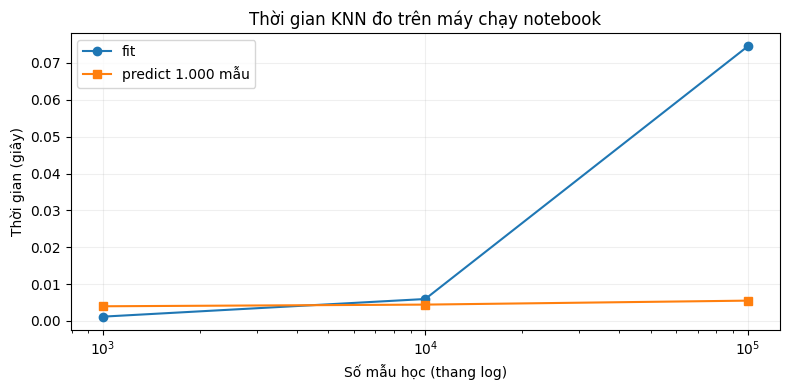

In [6]:
from pathlib import Path

# Tìm dataset từ thư mục bài, code/ hoặc Files trên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "hai_vang_trang.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)

import time
import numpy as np
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

rng = np.random.default_rng(0)
X_moi = rng.random((1000, 2))
ket_qua = []
for so_mau in [1000, 10000, 100000]:
    X_hoc = rng.random((so_mau, 2))
    # Nhãn nhị phân xác định từ hai đặc trưng; sinh dữ liệu nằm ngoài đoạn đo.
    y_hoc = (X_hoc[:, 0] + X_hoc[:, 1] > 1).astype(int)
    model = KNeighborsClassifier(n_neighbors=5)
    bat_dau = time.perf_counter()
    model.fit(X_hoc, y_hoc)
    thoi_gian_fit = time.perf_counter() - bat_dau
    bat_dau = time.perf_counter()
    nhan = model.predict(X_moi)
    thoi_gian_predict = time.perf_counter() - bat_dau
    ket_qua.append({"so_mau_hoc": so_mau, "fit_giay": thoi_gian_fit,
                    "predict_1000_giay": thoi_gian_predict})

bang_thoi_gian = pd.DataFrame(ket_qua)
print(bang_thoi_gian.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
print("Giải thích: KNN là học lười vì chủ yếu lưu các mẫu học; khi dự đoán mới tìm láng giềng và bỏ phiếu. Khi số mẫu tăng, việc lưu hoặc lập chỉ mục và tìm láng giềng có thể tốn thêm thời gian.")
print("Ở dữ liệu 2 chiều, algorithm='auto' có thể dùng cây tìm kiếm để tăng tốc, nên fit không chỉ là sao chép dữ liệu và thời gian predict không nhất thiết tăng tuyến tính. Một lần đo có thể dao động do máy; so sánh tương đối, không xem số giây là hằng số của thuật toán.")

# Hình minh họa bổ sung, giữ chung cell của mục này.
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(bang_thoi_gian.so_mau_hoc, bang_thoi_gian.fit_giay, "o-", label="fit")
plt.plot(bang_thoi_gian.so_mau_hoc, bang_thoi_gian.predict_1000_giay, "s-", label="predict 1.000 mẫu")
plt.xscale("log")
plt.xlabel("Số mẫu học (thang log)")
plt.ylabel("Thời gian (giây)")
plt.title("Thời gian KNN đo trên máy chạy notebook")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(thu_muc_hinh / "bai6_thoi_gian.png", dpi=150)
plt.show()
